# Collection and Visualization of ATAC-seq Data in ARPE-19 Cells for KR Library

The goal of this program is to write a Python function that takes a gRNA library as input, parses it, looks up ATAC-seq data from a publicly available reference dataset, and correlates that ATAC-seq data to each gRNA to make an accessibility metric.

In [27]:
# Install necessary libraries
%pip install ipykernel numpy pandas scikit-learn seaborn matplotlib mygene pyBigWig viennarna pyfaidx genomepy pybedtools

Note: you may need to restart the kernel to use updated packages.


In [28]:
!brew install bedtools

To reinstall 2.31.1, run:
  brew reinstall bedtools


In [29]:
# Import necessary libraries
import pandas as pd
import mygene
import pyBigWig

import matplotlib.pyplot as plt
import seaborn as sns

import genomepy
import pybedtools

import numpy as np
from scipy.stats import pearsonr, spearmanr

mg = mygene.MyGeneInfo()
# Connecting to the MyGeneInfo API

library = pd.read_csv("combined_libraries_prioritized_flat_top_distribution.csv")

### Finding the coordinate based on single guide ID

In [30]:
# COMMENT HERE
library['coordinate'] = library['sgID'].str.split('_').str[2]

# COMMENT HERE
library['coordinate'] = library['coordinate'].str.split('.').str[0]

# COMMENT HERE
library['coordinate'] = library['coordinate'].astype(int)

### Finding Chromosome of each gene

In [31]:
# COMMENT HERE
query_list = mg.querymany(
    library["gene"].drop_duplicates().tolist(),
    scopes="symbol",
    fields="genomic_pos_hg19",
    species="human",
    as_dataframe=False  
)

3 input query terms found no hit:	['C15orf48', 'FAM136A', 'GAS8']


In [32]:
gene_to_chr = {}

for hit in query_list:
    gene = hit.get('query')
    pos_data = hit.get('genomic_pos_hg19')
    
    if not gene or not pos_data:
        continue

    # Normalize to a list of dictionaries to eliminate redundant code
    pos_list = [pos_data] if isinstance(pos_data, dict) else pos_data
    
    if isinstance(pos_list, list) and len(pos_list) > 0:
        chrom = pos_list[0].get('chr')
        if chrom:
            chrom_str = str(chrom)
            # Standardize 'chr' prefix cleanly
            gene_to_chr[gene] = chrom_str if chrom_str.startswith('chr') else f"chr{chrom_str}"

# Map attributes back to the primary DataFrame
library["chromosome"] = library["gene"].map(gene_to_chr)

# DROPS UNMAPPED ENTRIES--IS THIS OK? 
# Note: Ensure library['gene_strand'] is created elsewhere in your pipeline
library = library.dropna(subset=['chromosome'])

## Querying and finding ATAC-seq Signal

In [33]:
def safe_bw_stats(bw, chrom, start, end, exact=True):
    """
    Safely get the mean signal for a region.
    Returns None if:
      - chromosome is missing
      - start >= end
      - interval is outside chromosome bounds
    Otherwise returns bw.stats()[0]
    """
    chrom_sizes = bw.chroms()

    # Check chromosome exists
    if chrom not in chrom_sizes:
        return None

    # Clip interval to chromosome bounds
    start = max(0, start)
    end = min(end, chrom_sizes[chrom])

    # Interval sanity
    if start >= end:
        return None

    return bw.stats(chrom, start, end, exact=exact)[0]

In [34]:
url = "data/GSE272247_ARPE_ATAC.bw"
bw_atac = pyBigWig.open(url)

library["ATAC_signal"] = [
    safe_bw_stats(bw_atac, chrom, int(start), int(end))
    for chrom, start, end in zip(
        library["chromosome"],
        library["coordinate"] - 250,
        library["coordinate"] + 250
    )
]

In [35]:
import numpy as np

# 1. Apply a log2(x + 1) transformation to the raw signal
library['log_ATAC'] = np.log2(library['ATAC_signal'] + 1)

# 2. Calculate the min and max of the NEW log-transformed data
log_min = library['log_ATAC'].min()
log_max = library['log_ATAC'].max()

# 3. Create your 0-1 ACCESSIBILITY variable based on the log valuesx
library['ACCESSIBILITY'] = (library['log_ATAC'] - log_min) / (log_max - log_min)

## Plotting the ATAC-seq Signal

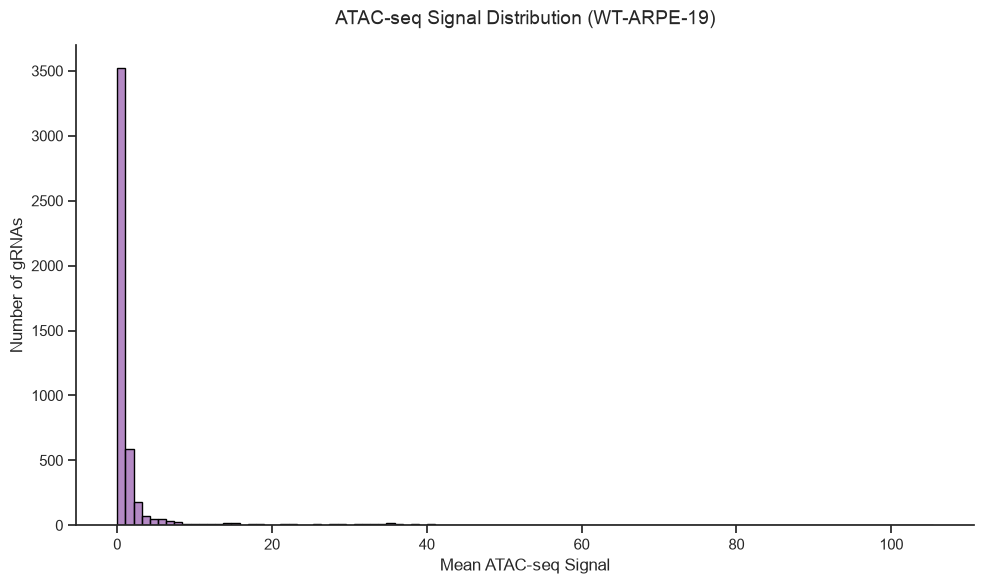

In [36]:
# Set the style to clean white background with no grid lines (matching the reference)
sns.set_theme(style="ticks")

# Create the figure with a similar widescreen aspect ratio
plt.figure(figsize=(10, 6))

# Plot the histogram for ATAC_signal (drop NaNs to avoid plotting errors)
sns.histplot(
    data=library.dropna(subset=['ATAC_signal']),
    x='ATAC_signal',
    color='#9b62b0',
    edgecolor='black',
    linewidth=1,
    bins=100  # Adjust bin count depending on data density/sparsity
)

# Set labels and title to match the typography structure
plt.title(
    "ATAC-seq Signal Distribution (WT-ARPE-19)", 
    fontsize=14, 
    pad=15
)
plt.xlabel("Mean ATAC-seq Signal", fontsize=12)
plt.ylabel("Number of gRNAs", fontsize=12)

# Remove the top and right borders (spines)
sns.despine()

# Tighten layout and display/save
plt.tight_layout()
plt.show()

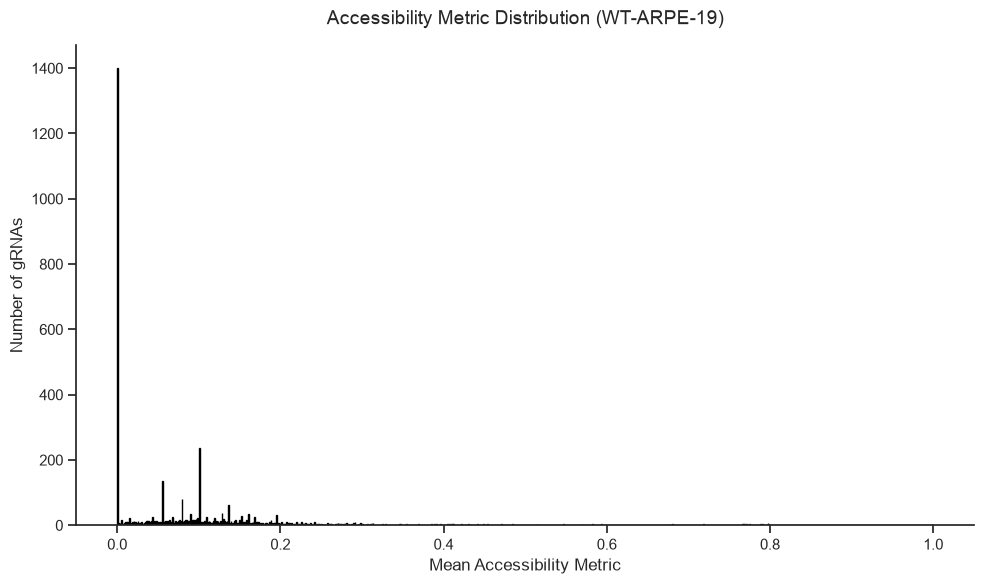

In [37]:
# Set the style to clean white background with no grid lines (matching the reference)
sns.set_theme(style="ticks")

# Create the figure with a similar widescreen aspect ratio
plt.figure(figsize=(10, 6))

# Plot the histogram for ATAC_signal (drop NaNs to avoid plotting errors)
sns.histplot(
    data=library.dropna(subset=['ACCESSIBILITY']),
    x='ACCESSIBILITY',
    color='#9b62b0',
    edgecolor='black',
    linewidth=1,
    bins=1000  # Adjust bin count depending on data density/sparsity
)

# Set labels and title to match the typography structure
plt.title(
    "Accessibility Metric Distribution (WT-ARPE-19)", 
    fontsize=14, 
    pad=15
)
plt.xlabel("Mean Accessibility Metric", fontsize=12)
plt.ylabel("Number of gRNAs", fontsize=12)

# Remove the top and right borders (spines)
sns.despine()

# Tighten layout and display/save
plt.tight_layout()
plt.show()

## Transcription Factor Binding Measure

In [38]:
# 1. Create a 500 bp window around each guide's target coordinate
library["start"] = library["coordinate"] - 250
library["end"] = library["coordinate"] + 250

# 2. Extract standard BED columns: chromosome, start, end, name (sgID)
grna_bed_df = library[["chromosome", "start", "end", "sgID"]]

# 3. Convert the pandas DataFrame into a BedTool object
grna_bed = pybedtools.BedTool.from_dataframe(grna_bed_df)

In [39]:
input_path = "remap2022_nr_macs2_hg19_v1_0.bed"
output_path = "remap2022_nr_macs2_hg19_v1_0_clean.bed"

print("Cleaning malformed rows from ReMap file...")
with open(input_path, "r") as infile, open(output_path, "w") as outfile:
    for line in infile:
        # ReMap uses standard tab separators
        fields = line.strip().split("\t")
        if len(fields) == 9:
            outfile.write(line)
        # Quietly skip any line that is malformed (like line 19,938,388)

print("Formatting clean! You now have a 100% compliant BED file.")

Cleaning malformed rows from ReMap file...
Formatting clean! You now have a 100% compliant BED file.


In [40]:
# 1. Define the path to your local downloaded ReMap file
# (Adjust the filename if yours ends with .gz)
remap_file = "/Users/higado/Documents/CRISPR Residence Time Prediction/remap2022_nr_macs2_hg19_v1_0_clean.bed" 

# 2. Initialize the ReMap BedTool object
remap_bed = pybedtools.BedTool(remap_file)

In [41]:
# 1. Perform the genomic intersection
intersection = grna_bed.intersect(remap_bed, wo=True)

In [42]:
# 1. Define the exact 14 columns we expect from the intersection
column_names = [
    "gRNA_chrom", "gRNA_start", "gRNA_end", "sgID",
    "peak_chrom", "peak_start", "peak_end", "tf_info",
    "score", "strand", "thickStart", "thickEnd", "itemRgb", "overlap_bp"
]

# 2. Convert to DataFrame and supply the names immediately to silence the warning
intersection_df = intersection.to_dataframe(names=column_names)

# 3. Clean up the TF names using the colon split
intersection_df["TF_name"] = intersection_df["tf_info"].apply(lambda x: str(x).split(":")[0])

In [43]:
import numpy as np

# ==========================================
# REVISED BLOCK 6: Group and unique as lists
# ==========================================

# Group by guide and force the unique TF names into a standard Python list
grna_tf_summary = (
    intersection_df.groupby("sgID")["TF_name"]
    .apply(lambda x: list(x.unique()))
    .reset_index()
)

# Calculate the count of unique TFs
grna_tf_summary["TF_count"] = grna_tf_summary["TF_name"].apply(len)


# ==========================================
# REVISED BLOCK 7: Map back to your 'library' DataFrame
# ==========================================

# Create mapping dictionaries
name_map = grna_tf_summary.set_index("sgID")["TF_name"].to_dict()
count_map = grna_tf_summary.set_index("sgID")["TF_count"].to_dict()

# Map values directly to your 'library' DataFrame 
# (If a guide has no overlaps, it safely defaults to [] and 0)
library["TF_name"] = library["sgID"].map(name_map).apply(lambda x: x if isinstance(x, list) else [])
library["TF_count"] = library["sgID"].map(count_map).fillna(0).astype(int)

In [44]:
library.to_csv("7.14.2026 - TFs as well.csv")

# MORE PLOTS

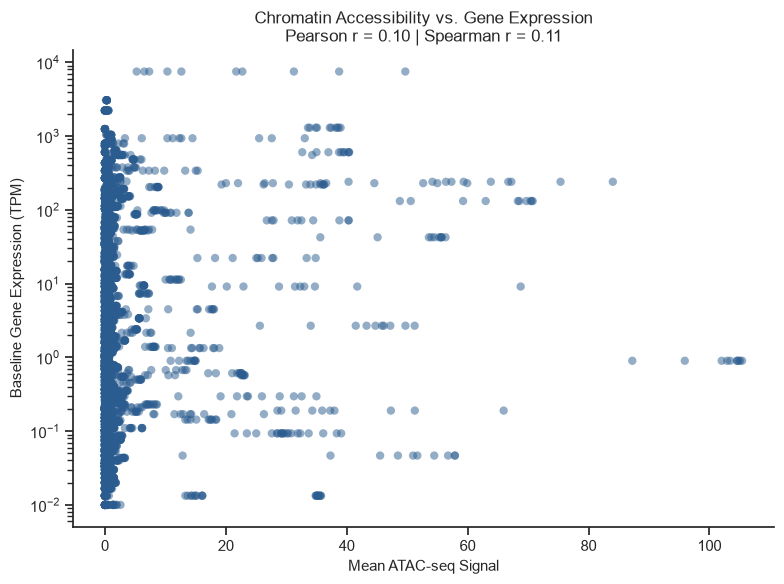

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Clean data
plot_df = library.dropna(subset=['ATAC_signal', 'control_mean_log_adjusted']).copy()

# Calculate correlation on the RAW data
corr_p, _ = pearsonr(plot_df['ATAC_signal'], plot_df['control_mean_log_adjusted'])
corr_s, _ = spearmanr(plot_df['ATAC_signal'], plot_df['control_mean_log_adjusted'])

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=plot_df, 
    x='ATAC_signal', 
    y='control_mean_log_adjusted', 
    alpha=0.5, 
    color='#2b5c8f', 
    edgecolor='none'
)

# Set the Y-axis to a logarithmic scale
plt.yscale('log')

plt.title(f"Chromatin Accessibility vs. Gene Expression\nPearson r = {corr_p:.2f} | Spearman r = {corr_s:.2f}", fontsize=12)
plt.xlabel("Mean ATAC-seq Signal", fontsize=11)
plt.ylabel("Baseline Gene Expression (TPM)", fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

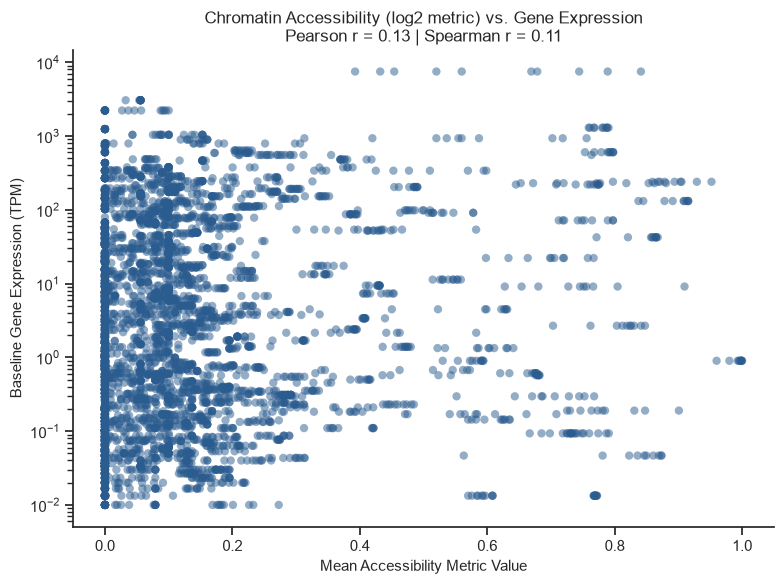

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Clean data
plot_df = library.dropna(subset=['ACCESSIBILITY', 'control_mean_log_adjusted']).copy()

# Calculate correlation on the RAW data
corr_p, _ = pearsonr(plot_df['ACCESSIBILITY'], plot_df['control_mean_log_adjusted'])
corr_s, _ = spearmanr(plot_df['ACCESSIBILITY'], plot_df['control_mean_log_adjusted'])

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=plot_df, 
    x='ACCESSIBILITY', 
    y='control_mean_log_adjusted', 
    alpha=0.5, 
    color='#2b5c8f', 
    edgecolor='none'
)

# Set the Y-axis to a logarithmic scale
plt.yscale('log')

plt.title(f"Chromatin Accessibility (log2 metric) vs. Gene Expression\nPearson r = {corr_p:.2f} | Spearman r = {corr_s:.2f}", fontsize=12)
plt.xlabel("Mean Accessibility Metric Value", fontsize=11)
plt.ylabel("Baseline Gene Expression (TPM)", fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

/var/folders/t_/3mm09t_s47x1zydjtbx5p6t40000gn/T/ipykernel_29509/2600994984.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(


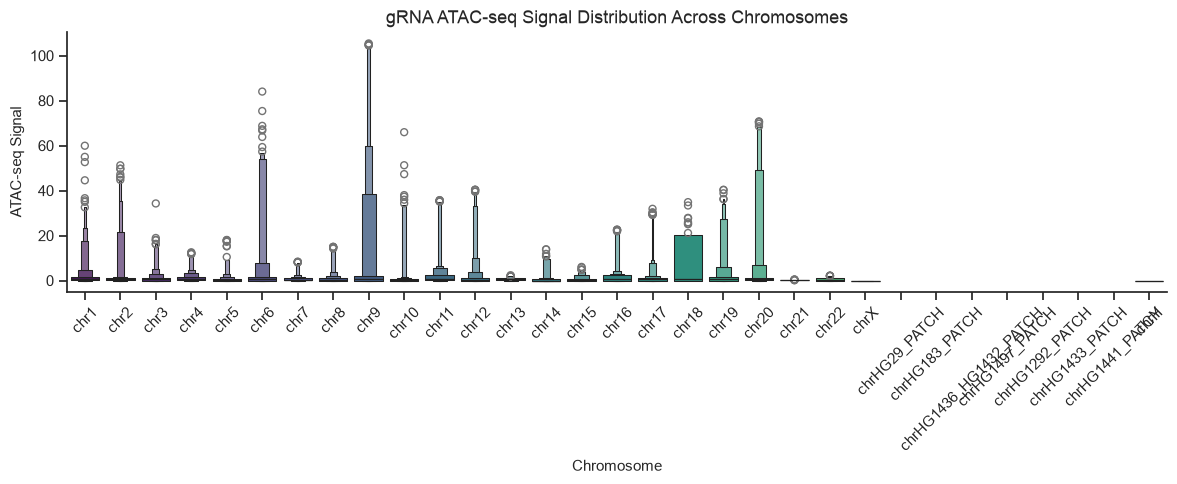

In [47]:
# Sort chromosomes numerically (chr1, chr2, ..., chrX)
chrom_order = sorted(library['chromosome'].unique(), key=lambda x: (int(x[3:]) if x[3:].isdigit() else 999))

plt.figure(figsize=(12, 5))
sns.boxenplot(
    data=library.dropna(subset=['ATAC_signal']),
    x='chromosome',
    y='ATAC_signal',
    order=chrom_order,
    palette="viridis"
)
plt.xticks(rotation=45)
plt.title("gRNA ATAC-seq Signal Distribution Across Chromosomes", fontsize=13)
plt.xlabel("Chromosome", fontsize=11)
plt.ylabel("ATAC-seq Signal", fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

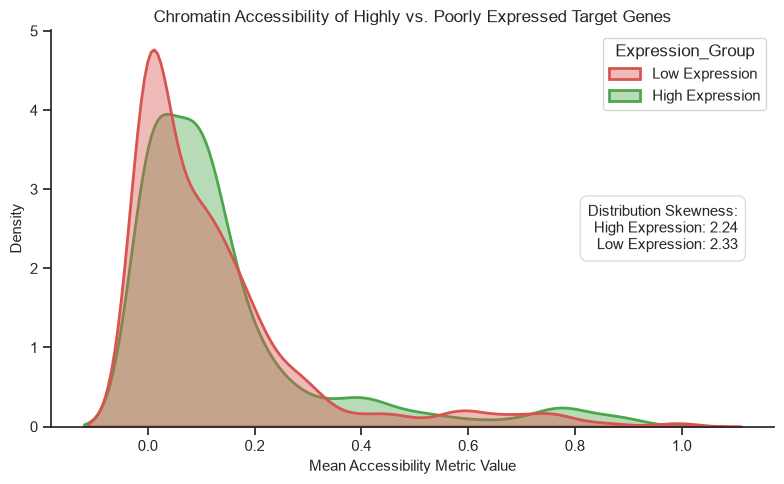

In [48]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

# 1. Clean the data first so calculations are accurate
plot_data = library.dropna(subset=['ACCESSIBILITY', 'control_mean_log_adjusted']).copy()

# 2. Define threshold and classify expression status
median_tpm = plot_data['control_mean_log_adjusted'].median()
plot_data['Expression_Group'] = np.where(
    plot_data['control_mean_log_adjusted'] >= median_tpm, 
    'High Expression', 
    'Low Expression'
)

# 3. Calculate the Skewness for both groups
skew_high = skew(plot_data[plot_data['Expression_Group'] == 'High Expression']['ACCESSIBILITY'])
skew_low = skew(plot_data[plot_data['Expression_Group'] == 'Low Expression']['ACCESSIBILITY'])

# 4. Generate the Plot
plt.figure(figsize=(8, 5))
sns.kdeplot(
    data=plot_data,
    x='ACCESSIBILITY',
    hue='Expression_Group',
    fill=True,
    common_norm=False,
    palette={'High Expression': '#4ca64c', 'Low Expression': '#d9534f'},
    alpha=0.4,
    linewidth=2
)

# 5. Format the Plot
plt.title("Chromatin Accessibility of Highly vs. Poorly Expressed Target Genes", fontsize=12)
plt.xlabel("Mean Accessibility Metric Value", fontsize=11)
plt.ylabel("Density", fontsize=11)

# 6. Add a text box displaying the skew values
skew_text = f"Distribution Skewness:\nHigh Expression: {skew_high:.2f}\nLow Expression: {skew_low:.2f}"

# You can adjust the x (0.95) and y (0.5) coordinates to move the box around
plt.text(
    0.95, 0.5, 
    skew_text, 
    transform=plt.gca().transAxes, 
    fontsize=11,
    verticalalignment='center', 
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='lightgray')
)

sns.despine()
plt.tight_layout()
plt.show()

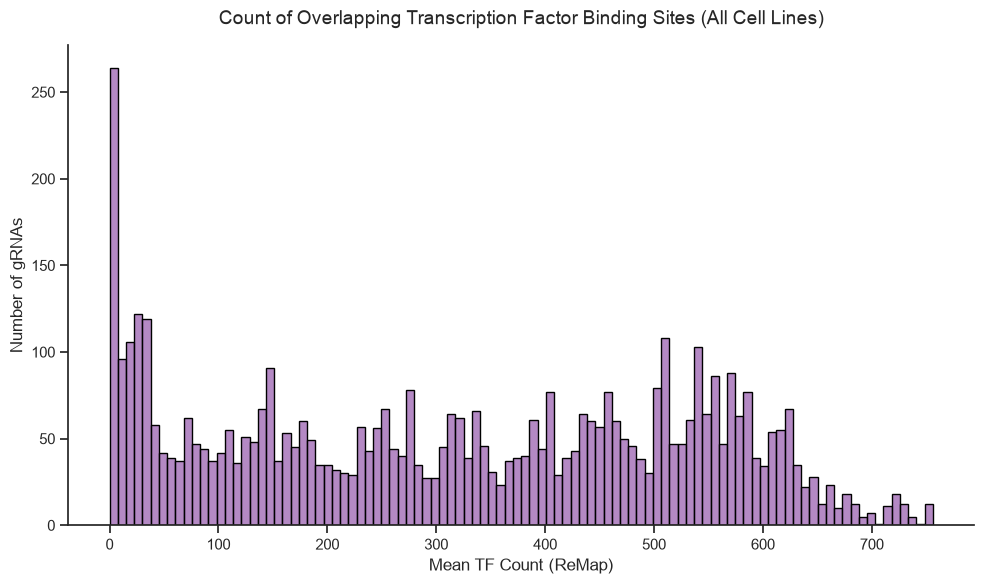

In [49]:
# Set the style to clean white background with no grid lines (matching the reference)
sns.set_theme(style="ticks")

# Create the figure with a similar widescreen aspect ratio
plt.figure(figsize=(10, 6))

# Plot the histogram for ATAC_signal (drop NaNs to avoid plotting errors)
sns.histplot(
    data=library.dropna(subset=['TF_count']),
    x='TF_count',
    color='#9b62b0',
    edgecolor='black',
    linewidth=1,
    bins=100  # Adjust bin count depending on data density/sparsity
)

# Set labels and title to match the typography structure
plt.title(
    "Count of Overlapping Transcription Factor Binding Sites (All Cell Lines)", 
    fontsize=14, 
    pad=15
)
plt.xlabel("Mean TF Count (ReMap)", fontsize=12)
plt.ylabel("Number of gRNAs", fontsize=12)

# Remove the top and right borders (spines)
sns.despine()

# Tighten layout and display/save
plt.tight_layout()
plt.show()

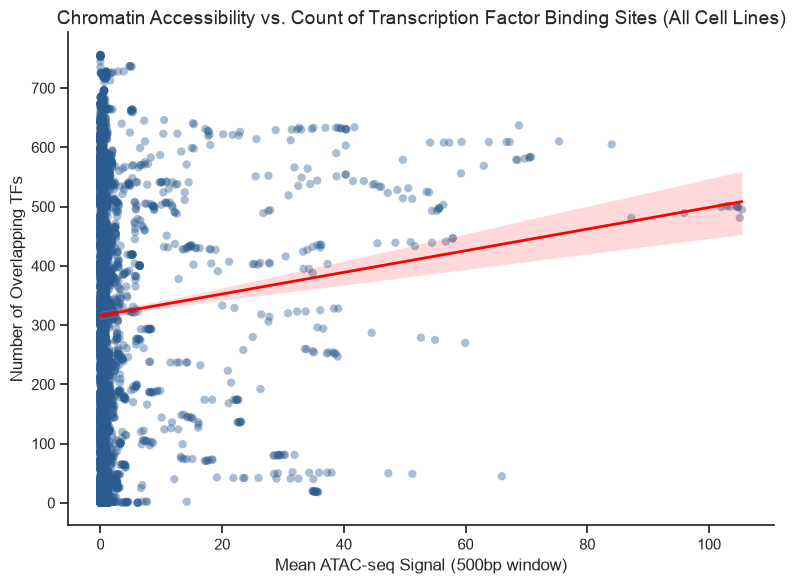

In [50]:
plt.figure(figsize=(8, 6))

# 1. Plot the scatter with a fitted linear regression line
sns.regplot(
    data=library.dropna(subset=['ATAC_signal', 'TF_count']),
    x='ATAC_signal',
    y='TF_count',
    scatter_kws={'alpha': 0.4, 'color': '#2b5c8f', 'edgecolor': 'none'},
    line_kws={'color': 'red', 'linewidth': 2}
)

# 2. Format the plot
plt.title("Chromatin Accessibility vs. Count of Transcription Factor Binding Sites (All Cell Lines)", fontsize=14)
plt.xlabel("Mean ATAC-seq Signal (500bp window)", fontsize=12)
plt.ylabel("Number of Overlapping TFs", fontsize=12)
sns.despine()
plt.tight_layout()
plt.show()

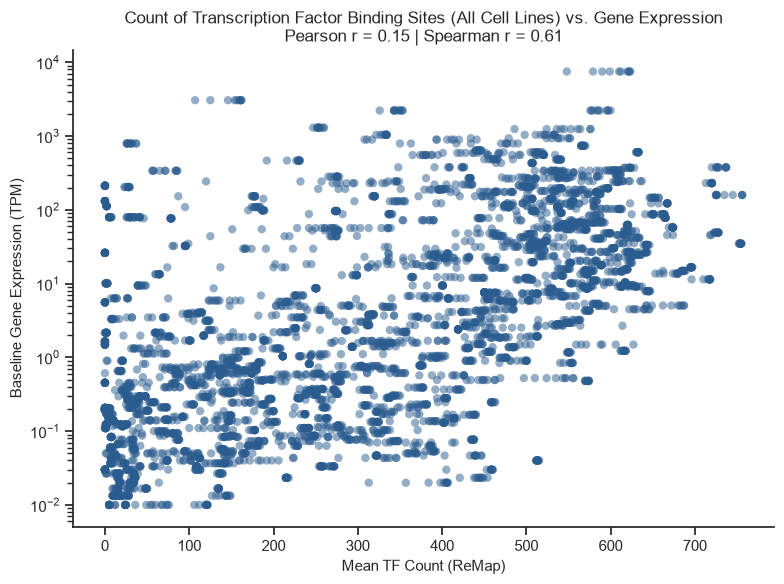

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Clean data
plot_df = library.dropna(subset=['TF_count', 'control_mean_log_adjusted']).copy()

# Calculate correlation on the RAW data
corr_p, _ = pearsonr(plot_df['TF_count'], plot_df['control_mean_log_adjusted'])
corr_s, _ = spearmanr(plot_df['TF_count'], plot_df['control_mean_log_adjusted'])

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=plot_df, 
    x='TF_count', 
    y='control_mean_log_adjusted', 
    alpha=0.5, 
    color='#2b5c8f', 
    edgecolor='none'
)

# Set the Y-axis to a logarithmic scale
plt.yscale('log')

plt.title(f"Count of Transcription Factor Binding Sites (All Cell Lines) vs. Gene Expression\nPearson r = {corr_p:.2f} | Spearman r = {corr_s:.2f}", fontsize=12)
plt.xlabel("Mean TF Count (ReMap)", fontsize=11)
plt.ylabel("Baseline Gene Expression (TPM)", fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

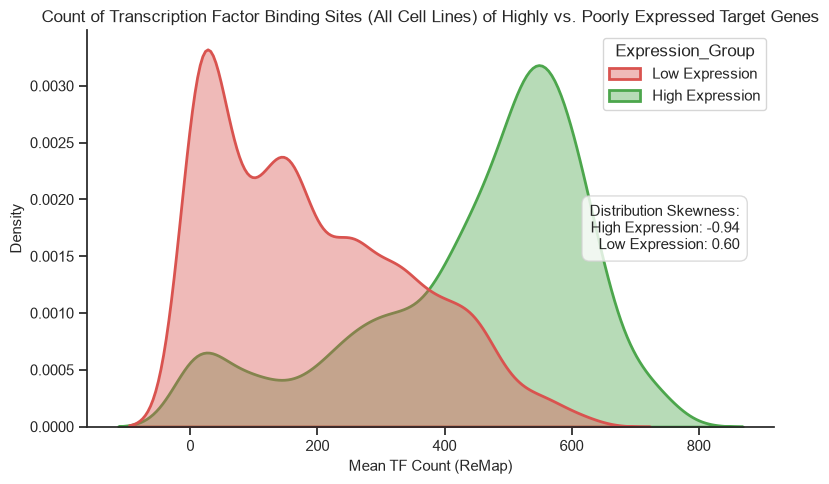

In [52]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

# 1. Clean the data first so calculations are accurate
plot_data = library.dropna(subset=['TF_count', 'control_mean_log_adjusted']).copy()

# 2. Define threshold and classify expression status
median_tpm = plot_data['control_mean_log_adjusted'].median()
plot_data['Expression_Group'] = np.where(
    plot_data['control_mean_log_adjusted'] >= median_tpm, 
    'High Expression', 
    'Low Expression'
)

# 3. Calculate the Skewness for both groups
skew_high = skew(plot_data[plot_data['Expression_Group'] == 'High Expression']['TF_count'])
skew_low = skew(plot_data[plot_data['Expression_Group'] == 'Low Expression']['TF_count'])

# 4. Generate the Plot
plt.figure(figsize=(8, 5))
sns.kdeplot(
    data=plot_data,
    x='TF_count',
    hue='Expression_Group',
    fill=True,
    common_norm=False,
    palette={'High Expression': '#4ca64c', 'Low Expression': '#d9534f'},
    alpha=0.4,
    linewidth=2
)

# 5. Format the Plot
plt.title("Count of Transcription Factor Binding Sites (All Cell Lines) of Highly vs. Poorly Expressed Target Genes", fontsize=12)
plt.xlabel("Mean TF Count (ReMap)", fontsize=11)
plt.ylabel("Density", fontsize=11)

# 6. Add a text box displaying the skew values
skew_text = f"Distribution Skewness:\nHigh Expression: {skew_high:.2f}\nLow Expression: {skew_low:.2f}"

# You can adjust the x (0.95) and y (0.5) coordinates to move the box around
plt.text(
    0.95, 0.5, 
    skew_text, 
    transform=plt.gca().transAxes, 
    fontsize=11,
    verticalalignment='center', 
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='lightgray')
)

sns.despine()
plt.tight_layout()
plt.show()